# Caso 07 — Ampara, seguros: ¿qué canal paga lo que cuesta?
## Día 5 — Que se entienda y cambie algo (Visualizaciones Ejecutivas y One-Pager para Marta)

En el cierre de la semana volvemos a **Python (Pandas + Seaborn)** para que el cuaderno de visualización sea totalmente autónomo: rehacemos la cadena de limpieza desde los ficheros originales (`normalizar canal y ramo`, `limpiar euros`, `deduplicar`, `filtrar primas e importes inválidos`) y calculamos las métricas del jueves (`loss ratio`, `combined ratio`, `renovación` y `margen técnico`).

Cada gráfico va acompañado del `print` de sus cifras exactas y sigue el orden narrativo diseñado para la demo ante **Marta Belmonte (CEO)** y **Álex Cordero (Head de Distribución)**:
1. **Gráfico 1 — Primero la razón, luego el golpe:** Cuota de Prima Suscrita (%) frente a Margen Técnico Total (€).
2. **Gráfico 2 — El porqué (mecanismo técnico):** Loss Ratio y Combined Ratio por canal con la línea crítica del 100%.
3. **Gráfico 3 — El cazador de precio no se queda:** Tasa de Renovación (%) y Margen Técnico por Póliza (€).
4. **Gráfico 4 — El escudo contra la corazonada de Lucía:** Control de confusión del Loss Ratio por canal dentro de cada ramo (`auto`, `salud`, `mascotas`, `hogar`, `vida`).


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path

RAW_DIR = Path("data/raw")
REPORTS_DIR = Path("reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# 1. Carga y cadena de limpieza completa en Pandas desde data/raw
productos = pd.read_csv(RAW_DIR / "productos.csv")
campanas = pd.read_csv(RAW_DIR / "campanas.csv")
polizas = pd.read_csv(RAW_DIR / "polizas.csv")
siniestros = pd.read_csv(RAW_DIR / "siniestros.csv")

def limpiar_euros(serie: pd.Series) -> pd.Series:
    limpia = (
        serie.astype(str)
        .str.replace("€", "", regex=False)
        .str.replace("\ufffd", "", regex=False)
        .str.strip()
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )
    return pd.to_numeric(limpia, errors="coerce")

mapa_canal_polizas = {
    "comparadores": "comparadores", "comparador": "comparadores", "rastreator": "comparadores", "agregador": "comparadores",
    "directo": "directo", "web": "directo", "app": "directo", "online": "directo",
    "mediadores": "mediadores", "mediador": "mediadores", "corredor": "mediadores", "agente": "mediadores",
    "banca": "banca", "bancaseguros": "banca", "banco": "banca",
    "referido": "referido", "recomendacion": "referido", "recomendación": "referido", "amigo": "referido",
}
mapa_canal_campanas = {
    **mapa_canal_polizas,
    "ads": "directo", "paid": "directo",
    "comision": "mediadores", "comisión": "mediadores",
    "acuerdo": "banca", "recompensa": "referido",
}
mapa_ramo = {
    "automovil": "auto", "automóvil": "auto", "auto": "auto",
    "vivienda": "hogar", "hogar": "hogar",
    "salud": "salud", "vida": "vida",
    "mascota": "mascotas", "mascotas": "mascotas",
}
mapa_tipo_poliza = {
    "nueva": "nueva", "alta": "nueva",
    "renovacion": "renovacion", "renovación": "renovacion", "renov": "renovacion", "renovada": "renovacion",
}

polizas["canal"] = polizas["canal"].astype(str).str.strip().str.lower().map(mapa_canal_polizas)
polizas["tipo"] = polizas["tipo"].astype(str).str.strip().str.lower().map(mapa_tipo_poliza)
polizas["prima_anual"] = limpiar_euros(polizas["prima_anual"])
polizas = polizas.drop_duplicates(subset=["poliza_id"], keep="first")
polizas = polizas[polizas["prima_anual"] > 0].copy()

campanas["canal"] = campanas["canal"].astype(str).str.strip().str.lower().map(mapa_canal_campanas)
campanas["coste"] = limpiar_euros(campanas["coste"])

productos["ramo"] = productos["nombre"].astype(str).str.strip().str.lower().map(mapa_ramo)

siniestros["importe"] = limpiar_euros(siniestros["importe"])
siniestros = siniestros.drop_duplicates(subset=["siniestro_id"], keep="first")
siniestros = siniestros[(siniestros["importe"] > 0) & (siniestros["importe"] < 1_000_000)].copy()

# 2. Cálculo de las métricas por canal sobre las 60.000 pólizas nuevas
nuevas = polizas[polizas["tipo"] == "nueva"].copy()
origenes_renovados = set(polizas["poliza_origen_id"].dropna().astype(int).unique())
nuevas["renovada"] = nuevas["poliza_id"].isin(origenes_renovados)

agg_pol = nuevas.groupby("canal", as_index=False).agg(
    polizas_nuevas=("poliza_id", "count"),
    prima_total=("prima_anual", "sum"),
    prima_media=("prima_anual", "mean"),
    renovacion_pct=("renovada", lambda s: s.mean() * 100),
)
agg_pol["cuota_polizas_pct"] = agg_pol["polizas_nuevas"] / agg_pol["polizas_nuevas"].sum() * 100
agg_pol["cuota_prima_pct"] = agg_pol["prima_total"] / agg_pol["prima_total"].sum() * 100

siniestros_nuevas = nuevas[["poliza_id", "canal"]].merge(siniestros, on="poliza_id", how="inner")
agg_sin = siniestros_nuevas.groupby("canal", as_index=False).agg(
    siniestros_total=("importe", "sum"),
    n_siniestros=("siniestro_id", "count"),
)
agg_camp = campanas.groupby("canal", as_index=False).agg(coste_campanas=("coste", "sum"))

df_resumen = agg_pol.merge(agg_sin, on="canal", how="left").merge(agg_camp, on="canal", how="left")
df_resumen["cac_eur"] = df_resumen["coste_campanas"] / df_resumen["polizas_nuevas"]
df_resumen["loss_ratio_pct"] = (df_resumen["siniestros_total"] / df_resumen["prima_total"]) * 100
df_resumen["gastos_pct"] = 22.0
df_resumen["cac_pct"] = (df_resumen["cac_eur"] / df_resumen["prima_media"]) * 100
df_resumen["combined_ratio_pct"] = df_resumen["loss_ratio_pct"] + df_resumen["gastos_pct"] + df_resumen["cac_pct"]
df_resumen["margen_poliza_eur"] = df_resumen["prima_media"] * (1.0 - df_resumen["combined_ratio_pct"] / 100.0)
df_resumen["margen_total_eur"] = df_resumen["margen_poliza_eur"] * df_resumen["polizas_nuevas"]

orden_canales = ["comparadores", "directo", "mediadores", "banca", "referido"]
df_resumen["canal"] = pd.Categorical(df_resumen["canal"], categories=orden_canales, ordered=True)
df_resumen = df_resumen.sort_values("canal").reset_index(drop=True)

display(df_resumen.round(2))


,canal,polizas_nuevas,prima_total,prima_media,renovacion_pct,cuota_polizas_pct,cuota_prima_pct,siniestros_total,n_siniestros,coste_campanas,cac_eur,loss_ratio_pct,gastos_pct,cac_pct,combined_ratio_pct,margen_poliza_eur,margen_total_eur
0,comparadores,24000,11520000.07,480.0,41.0,40.0,40.25,9446400.50,53002,360000.0,15.0,82.0,22.0,3.12,107.13,-34.2,-820800.45
1,directo,13200,5543999.73,420.0,62.0,22.0,19.37,3769919.67,27048,396000.0,30.0,68.0,22.0,7.14,97.14,12.0,158400.12
2,mediadores,10800,6587999.95,610.0,78.0,18.0,23.02,3557519.86,19364,972000.0,90.0,54.0,22.0,14.75,90.75,56.4,609120.10
3,banca,7200,2807999.68,390.0,71.0,12.0,9.81,1628639.81,13545,324000.0,45.0,58.0,22.0,11.54,91.54,33.0,237599.94
4,referido,4800,2159999.95,450.0,80.0,8.0,7.55,1036800.16,9520,96000.0,20.0,48.0,22.0,4.44,74.44,115.0,551999.80


### 1. El Gráfico que Cambia el Presupuesto: Cuota de Prima (%) vs. Margen Técnico Total (€)
Primero le damos la razón a Álex en lo que la tiene (panel izquierdo: `comparadores` lidera la prima suscrita con el **40,25%** y $24.000$ pólizas), y al lado mostramos el golpe (panel derecho: `comparadores` es la única barra por debajo de cero, restando **`-820.800 €`** al margen de Ampara).


=== CIFRAS DEL GRÁFICO 1: CUOTA DE PRIMA vs MARGEN TÉCNICO TOTAL ===
- comparadores : 24,000 pólizas (40.0%) | Cuota prima: 40.25% (11,520,000.07 €) | Margen total: -820,800.45 € (-34.20 €/pól)
- directo      : 13,200 pólizas (22.0%) | Cuota prima: 19.37% (5,543,999.73 €) | Margen total: +158,400.12 € (+12.00 €/pól)
- mediadores   : 10,800 pólizas (18.0%) | Cuota prima: 23.02% (6,587,999.95 €) | Margen total: +609,120.10 € (+56.40 €/pól)
- banca        :  7,200 pólizas (12.0%) | Cuota prima:  9.81% (2,807,999.68 €) | Margen total: +237,599.94 € (+33.00 €/pól)
- referido     :  4,800 pólizas ( 8.0%) | Cuota prima:  7.55% (2,159,999.95 €) | Margen total: +551,999.80 € (+115.00 €/pól)


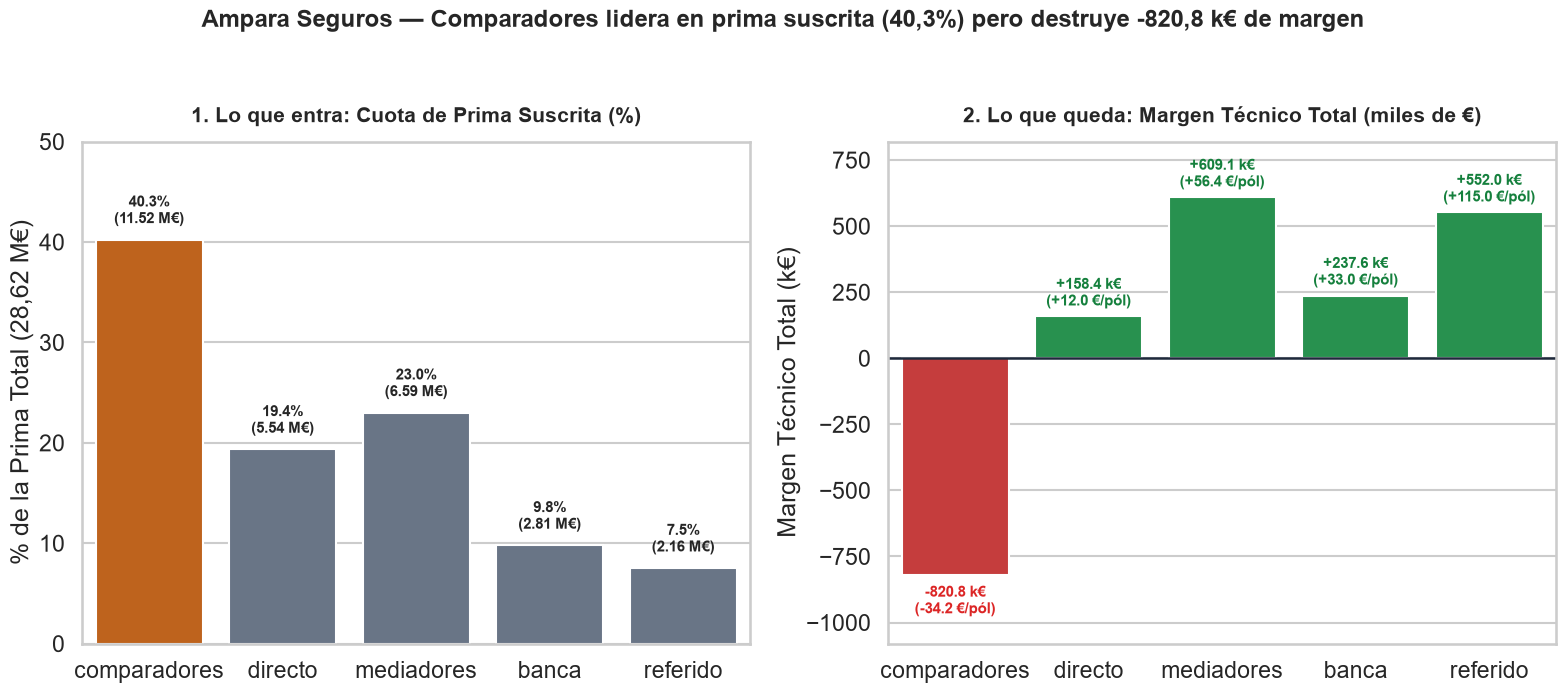

In [2]:
sns.set_theme(style="whitegrid", context="talk")
PALETA_CANALES = {
    "comparadores": "#D95F02",
    "directo": "#7570B3",
    "mediadores": "#1B9E77",
    "banca": "#66A61E",
    "referido": "#2B8CBE",
}

print("=== CIFRAS DEL GRÁFICO 1: CUOTA DE PRIMA vs MARGEN TÉCNICO TOTAL ===")
for _, r in df_resumen.iterrows():
    print(f"- {r['canal']:13s}: {int(r['polizas_nuevas']):6,d} pólizas ({r['cuota_polizas_pct']:4.1f}%) | Cuota prima: {r['cuota_prima_pct']:5.2f}% ({r['prima_total']:11,.2f} €) | Margen total: {r['margen_total_eur']:+11,.2f} € ({r['margen_poliza_eur']:+6.2f} €/pól)")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.8))

colores_izq = ["#D95F02" if c == "comparadores" else "#64748B" for c in df_resumen["canal"]]
sns.barplot(
    data=df_resumen, x="canal", y="cuota_prima_pct",
    hue="canal", palette=colores_izq, dodge=False, legend=False, ax=axes[0]
)
axes[0].set_title("1. Lo que entra: Cuota de Prima Suscrita (%)", fontsize=15, fontweight="bold", pad=14)
axes[0].set_xlabel("")
axes[0].set_ylabel("% de la Prima Total (28,62 M€)")
axes[0].set_ylim(0, 50)
for idx, row in df_resumen.iterrows():
    axes[0].text(
        idx, row["cuota_prima_pct"] + 1.2,
        f"{row['cuota_prima_pct']:.1f}%\n({row['prima_total']/1e6:.2f} M€)",
        ha="center", va="bottom", fontsize=11, fontweight="bold"
    )

colores_der = ["#DC2626" if v < 0 else "#16A34A" for v in df_resumen["margen_total_eur"]]
sns.barplot(
    data=df_resumen, x="canal", y=df_resumen["margen_total_eur"] / 1000.0,
    hue="canal", palette=colores_der, dodge=False, legend=False, ax=axes[1]
)
axes[1].axhline(0, color="#1E293B", linewidth=1.8)
axes[1].set_title("2. Lo que queda: Margen Técnico Total (miles de €)", fontsize=15, fontweight="bold", pad=14)
axes[1].set_xlabel("")
axes[1].set_ylabel("Margen Técnico Total (k€)")
axes[1].set_ylim(-1080, 820)
for idx, row in df_resumen.iterrows():
    val_k = row["margen_total_eur"] / 1000.0
    offset = -35 if val_k < 0 else 25
    axes[1].text(
        idx, val_k + offset,
        f"{val_k:+,.1f} k€\n({row['margen_poliza_eur']:+.1f} €/pól)",
        ha="center", va="bottom" if val_k >= 0 else "top",
        fontsize=11, fontweight="bold",
        color="#DC2626" if val_k < 0 else "#15803D"
    )

fig.suptitle("Ampara Seguros — Comparadores lidera en prima suscrita (40,3%) pero destruye -820,8 k€ de margen", fontsize=17, fontweight="bold", y=1.03)
plt.tight_layout()
fig.savefig(REPORTS_DIR / "01_cuota_prima_vs_margen_total.png", dpi=200, bbox_inches="tight")
plt.show()


### 2. El Porqué: Loss Ratio y Combined Ratio frente a la Línea del 100%
Explicamos el mecanismo técnico: `comparadores` tiene un **Loss Ratio del 82,0%** (casi el doble que el 48,0% de `referido`) y, al sumar el 22% de gastos de gestión y el CAC sobre prima (3,12%), es el **único canal que supera el 100% de Combined Ratio (107,13%)**.


=== CIFRAS DEL GRÁFICO 2: LOSS RATIO Y COMBINED RATIO POR CANAL ===
- comparadores : Loss Ratio = 82.00% | + Gastos 22,00% | + CAC/Prima  3.12% -> Combined Ratio = 107.13%
- directo      : Loss Ratio = 68.00% | + Gastos 22,00% | + CAC/Prima  7.14% -> Combined Ratio =  97.14%
- mediadores   : Loss Ratio = 54.00% | + Gastos 22,00% | + CAC/Prima 14.75% -> Combined Ratio =  90.75%
- banca        : Loss Ratio = 58.00% | + Gastos 22,00% | + CAC/Prima 11.54% -> Combined Ratio =  91.54%
- referido     : Loss Ratio = 48.00% | + Gastos 22,00% | + CAC/Prima  4.44% -> Combined Ratio =  74.44%


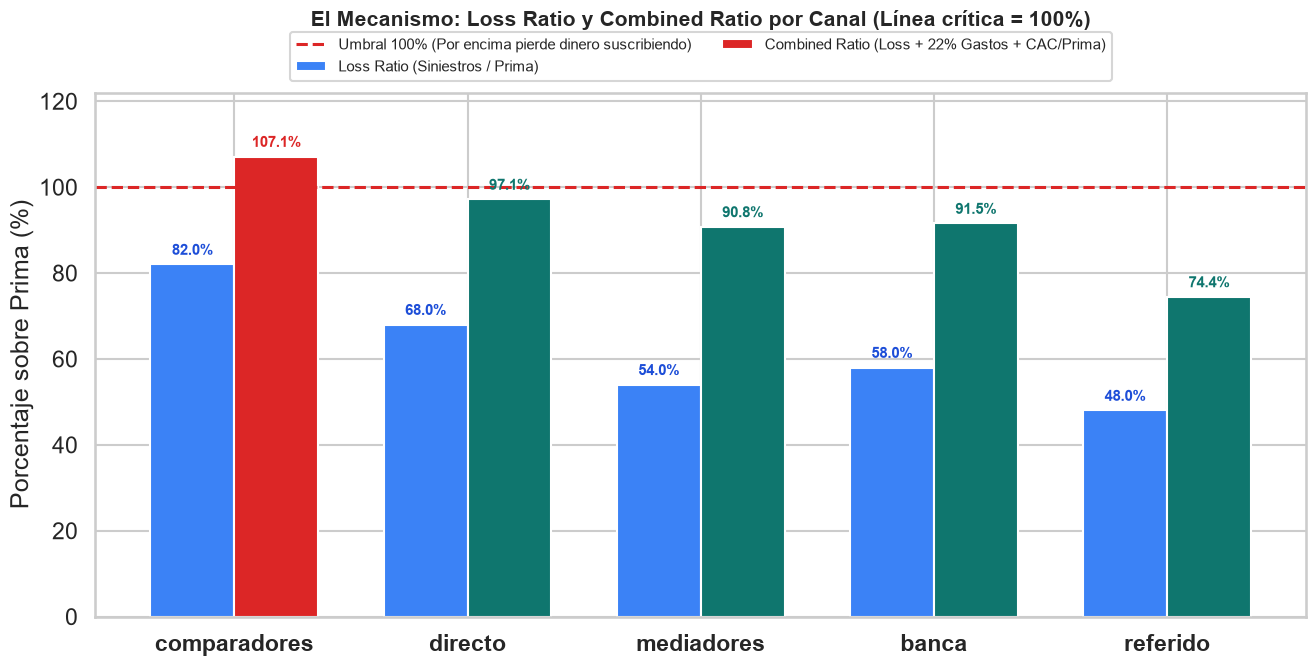

In [3]:
print("=== CIFRAS DEL GRÁFICO 2: LOSS RATIO Y COMBINED RATIO POR CANAL ===")
for _, r in df_resumen.iterrows():
    print(f"- {r['canal']:13s}: Loss Ratio = {r['loss_ratio_pct']:5.2f}% | + Gastos 22,00% | + CAC/Prima {r['cac_pct']:5.2f}% -> Combined Ratio = {r['combined_ratio_pct']:6.2f}%")

fig, ax = plt.subplots(figsize=(13.5, 7.0))
x = np.arange(len(df_resumen))
width = 0.36

rects1 = ax.bar(x - width/2, df_resumen["loss_ratio_pct"], width, label="Loss Ratio (Siniestros / Prima)", color="#3B82F6")
rects2 = ax.bar(
    x + width/2, df_resumen["combined_ratio_pct"], width,
    label="Combined Ratio (Loss + 22% Gastos + CAC/Prima)",
    color=["#DC2626" if v > 100 else "#0F766E" for v in df_resumen["combined_ratio_pct"]],
)

ax.axhline(100, color="#DC2626", linestyle="--", linewidth=2.2, label="Umbral 100% (Por encima pierde dinero suscribiendo)")
ax.set_title("El Mecanismo: Loss Ratio y Combined Ratio por Canal (Línea crítica = 100%)", fontsize=15, fontweight="bold", pad=48)
ax.set_xticks(x)
ax.set_xticklabels(df_resumen["canal"], fontweight="bold")
ax.set_ylabel("Porcentaje sobre Prima (%)")
ax.set_ylim(0, 122)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.13), ncol=2, frameon=True, fontsize=11)

for r in rects1:
    h = r.get_height()
    ax.text(r.get_x() + r.get_width()/2, h + 1.5, f"{h:.1f}%", ha="center", va="bottom", fontsize=11, color="#1D4ED8", fontweight="bold")

for r in rects2:
    h = r.get_height()
    ax.text(r.get_x() + r.get_width()/2, h + 1.5, f"{h:.1f}%", ha="center", va="bottom", fontsize=11, color="#DC2626" if h > 100 else "#0F766E", fontweight="bold")

plt.tight_layout()
fig.savefig(REPORTS_DIR / "02_loss_y_combined_ratio_canal.png", dpi=200, bbox_inches="tight")
plt.show()


### 3. El Cazador de Precio No Se Queda: Tasa de Renovación (%) y Margen por Póliza (€)
Rematamos la cadena causal mostrando que los clientes de `comparadores` no solo pierden dinero el primer año, sino que **solo renuevan el 41,0%** (frente al **80,0%** de `referido` y el **78,0%** de `mediadores`), y respondemos la pregunta directa de Marta: *«¿y eso en margen por póliza cuánto es?»* (`-34,20 €/póliza`).


=== CIFRAS DEL GRÁFICO 3: RENOVACIÓN (%) Y MARGEN POR PÓLIZA (€) ===
- comparadores : Renovación =  41.0% | CAC =  15.0 € | Margen por póliza =  -34.20 €
- directo      : Renovación =  62.0% | CAC =  30.0 € | Margen por póliza =  +12.00 €
- mediadores   : Renovación =  78.0% | CAC =  90.0 € | Margen por póliza =  +56.40 €
- banca        : Renovación =  71.0% | CAC =  45.0 € | Margen por póliza =  +33.00 €
- referido     : Renovación =  80.0% | CAC =  20.0 € | Margen por póliza = +115.00 €


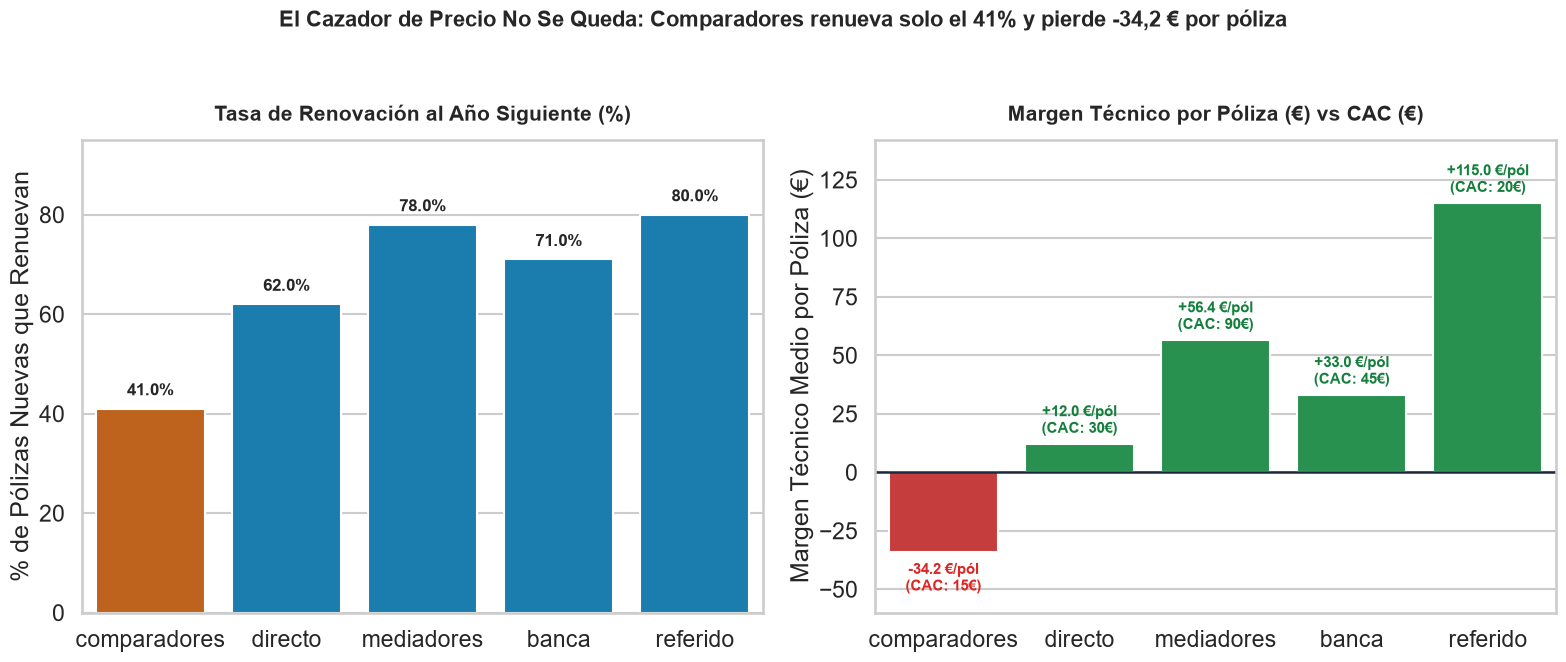

In [4]:
print("=== CIFRAS DEL GRÁFICO 3: RENOVACIÓN (%) Y MARGEN POR PÓLIZA (€) ===")
for _, r in df_resumen.iterrows():
    print(f"- {r['canal']:13s}: Renovación = {r['renovacion_pct']:5.1f}% | CAC = {r['cac_eur']:5.1f} € | Margen por póliza = {r['margen_poliza_eur']:+7.2f} €")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

colores_ren = ["#D95F02" if c == "comparadores" else "#0284C7" for c in df_resumen["canal"]]
sns.barplot(
    data=df_resumen, x="canal", y="renovacion_pct",
    hue="canal", palette=colores_ren, dodge=False, legend=False, ax=axes[0]
)
axes[0].set_title("Tasa de Renovación al Año Siguiente (%)", fontsize=15, fontweight="bold", pad=14)
axes[0].set_xlabel("")
axes[0].set_ylabel("% de Pólizas Nuevas que Renuevan")
axes[0].set_ylim(0, 95)
for idx, row in df_resumen.iterrows():
    axes[0].text(idx, row["renovacion_pct"] + 2, f"{row['renovacion_pct']:.1f}%", ha="center", va="bottom", fontsize=12, fontweight="bold")

colores_mp = ["#DC2626" if v < 0 else "#16A34A" for v in df_resumen["margen_poliza_eur"]]
sns.barplot(
    data=df_resumen, x="canal", y="margen_poliza_eur",
    hue="canal", palette=colores_mp, dodge=False, legend=False, ax=axes[1]
)
axes[1].axhline(0, color="#1E293B", linewidth=1.8)
axes[1].set_title("Margen Técnico por Póliza (€) vs CAC (€)", fontsize=15, fontweight="bold", pad=14)
axes[1].set_xlabel("")
axes[1].set_ylabel("Margen Técnico Medio por Póliza (€)")
axes[1].set_ylim(-60, 142)
for idx, row in df_resumen.iterrows():
    v = row["margen_poliza_eur"]
    offset = -4 if v < 0 else 3
    axes[1].text(
        idx, v + offset,
        f"{v:+.1f} €/pól\n(CAC: {row['cac_eur']:.0f}€)",
        ha="center", va="bottom" if v >= 0 else "top",
        fontsize=11, fontweight="bold",
        color="#DC2626" if v < 0 else "#15803D"
    )

fig.suptitle("El Cazador de Precio No Se Queda: Comparadores renueva solo el 41% y pierde -34,2 € por póliza", fontsize=16, fontweight="bold", y=1.03)
plt.tight_layout()
fig.savefig(REPORTS_DIR / "03_renovacion_y_margen_poliza.png", dpi=200, bbox_inches="tight")
plt.show()


### 4. El Escudo contra la Objeción de Lucía: Control de Confusión por Ramo
Desmontamos visualmente la corazonada del ramo de `auto`: dentro de cada uno de los cinco ramos, `comparadores` tiene un *loss ratio* entre **23 y 31 puntos porcentuales superior** al de `referido`. No es el producto que vende, es la calidad de riesgo que selecciona el canal.


=== CIFRAS DEL GRÁFICO 4: LOSS RATIO (%) POR CANAL DENTRO DE CADA RAMO ===


canal,comparadores,directo,mediadores,banca,referido,brecha_comp_vs_ref_pp
ramo,,,,,,
auto,89.71,79.38,67.49,70.80,58.76,30.95
salud,73.99,63.79,55.88,56.83,47.17,26.82
mascotas,68.56,56.78,49.45,53.39,41.08,27.48
hogar,58.55,49.11,42.07,45.89,35.41,23.14
vida,53.57,44.05,42.43,43.36,30.50,23.07


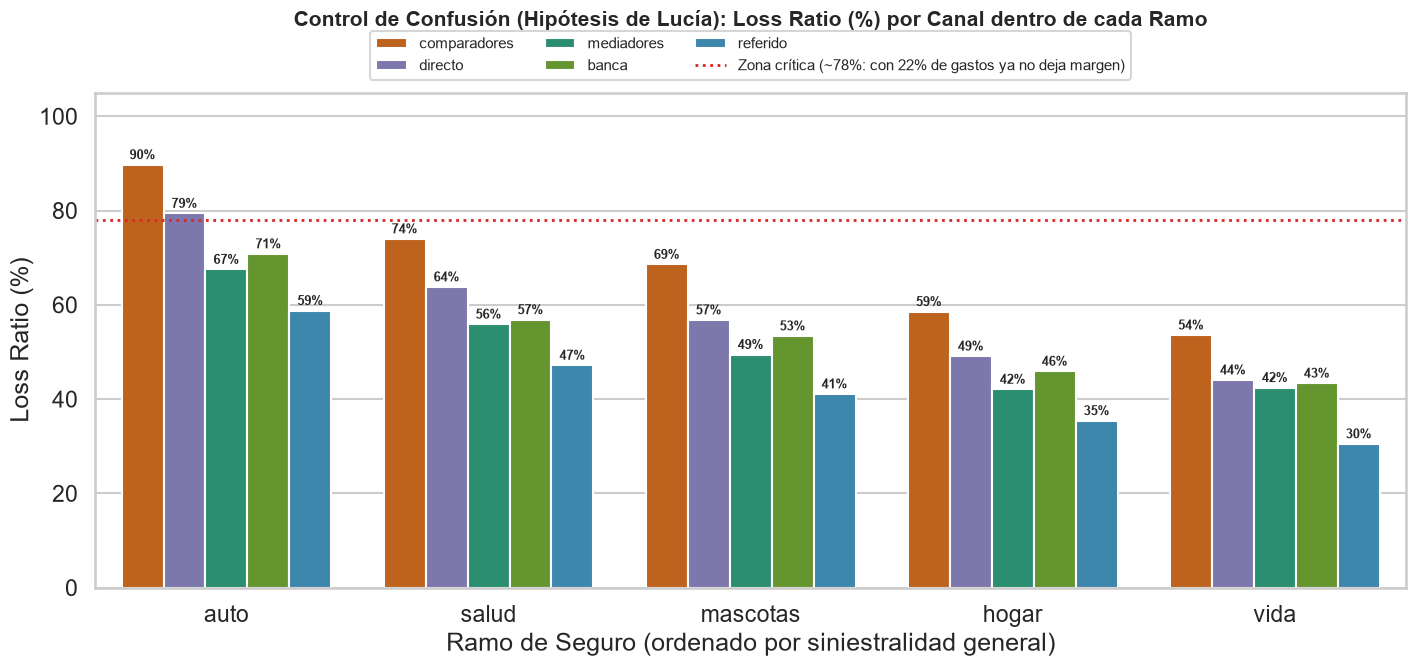

In [5]:
nuevas_ramo = nuevas.merge(productos[["producto_id", "ramo"]], on="producto_id", how="left")
prima_cr = nuevas_ramo.groupby(["ramo", "canal"], as_index=False).agg(prima_total=("prima_anual", "sum"))
sin_cr = (
    nuevas_ramo[["poliza_id", "ramo", "canal"]]
    .merge(siniestros, on="poliza_id", how="inner")
    .groupby(["ramo", "canal"], as_index=False)
    .agg(siniestros_total=("importe", "sum"))
)
df_cr = prima_cr.merge(sin_cr, on=["ramo", "canal"], how="left")
df_cr["loss_ratio_pct"] = (df_cr["siniestros_total"] / df_cr["prima_total"]) * 100

orden_ramos = ["auto", "salud", "mascotas", "hogar", "vida"]
df_cr["ramo"] = pd.Categorical(df_cr["ramo"], categories=orden_ramos, ordered=True)
df_cr["canal"] = pd.Categorical(df_cr["canal"], categories=orden_canales, ordered=True)

piv_cr = df_cr.pivot(index="ramo", columns="canal", values="loss_ratio_pct").round(2)
piv_cr["brecha_comp_vs_ref_pp"] = (piv_cr["comparadores"] - piv_cr["referido"]).round(2)
print("=== CIFRAS DEL GRÁFICO 4: LOSS RATIO (%) POR CANAL DENTRO DE CADA RAMO ===")
display(piv_cr)

fig, ax = plt.subplots(figsize=(14.5, 7.0))
sns.barplot(
    data=df_cr, x="ramo", y="loss_ratio_pct",
    hue="canal", palette=PALETA_CANALES, ax=ax
)
ax.axhline(78, color="#DC2626", linestyle=":", linewidth=2.0, label="Zona crítica (~78%: con 22% de gastos ya no deja margen)")
ax.set_title("Control de Confusión (Hipótesis de Lucía): Loss Ratio (%) por Canal dentro de cada Ramo", fontsize=15, fontweight="bold", pad=48)
ax.set_xlabel("Ramo de Seguro (ordenado por siniestralidad general)")
ax.set_ylabel("Loss Ratio (%)")
ax.set_ylim(0, 105)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.14), ncol=3, frameon=True, fontsize=11)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", padding=2, fontsize=9.5, fontweight="bold")

plt.tight_layout()
fig.savefig(REPORTS_DIR / "04_control_confusion_ramo.png", dpi=200, bbox_inches="tight")
plt.show()


---
## 5. El One-Pager para Marta Belmonte (CEO): Tres Hallazgos y Una Recomendación

1. **Álex tiene razón en la superficie (lo que entra):**
   Los **comparadores** son el canal número uno en pólizas nuevas ($24.000$, el **40,0%**), en prima suscrita ($11,52	ext{ M€}$, el **40,25%**), en prima media ($480	ext{ €}$) y el más barato de captar (**CAC de $15	ext{ €}$**). Es el líder indiscutible en captación de volumen, pero mide lo que entra y no lo que queda.
2. **Al mirar el margen técnico, los comparadores se hunden por selección adversa (lo que cuesta):**
   El precio bajo en el agregador selecciona a *cazadores de precio* que siniestran casi tanto como pagan (**Loss Ratio del 82,0%**, frente al 48,0% del referido), llevan al canal a perder dinero en la propia suscripción (**Combined Ratio del 107,1%**, el único por encima del 100%), y se marchan al año siguiente (**renovación del 41,0%**, la más baja de todas). Como resultado, es el **único canal con margen negativo: `−34,20 €` por póliza**.
3. **El número que decide el presupuesto (`−820.800 €`):**
   Con $24.000$ pólizas a $−34,20	ext{ €}$, los comparadores **restan `820.800 €` al margen técnico de Ampara** pese a traer el 40% de la prima. Hoy Ampara genera **$+736.320	ext{ €}$** de margen total; **sin los comparadores generaría `$+1.557.120 €$` (más del doble)**. Por el contrario, `mediadores` (a pesar de su CAC de $90	ext{ €}$) aporta **$+609.120	ext{ €}$** ($+56,40	ext{ €/póliza}$) y el pequeño canal `referido` (8% de las pólizas) aporta **$+552.000	ext{ €}$** ($+115,00	ext{ €/póliza}$).
   - *Nota de control:* **No es el ramo de auto** (la brecha de ~23	ext{--}31	ext{ pp} en *loss ratio* entre comparadores y referido se mantiene en los 5 ramos), **ni es el fraude** (uniforme en ~5	ext{--}6%), **ni la provincia o el descuento**. Es la calidad de riesgo del canal.

### Recomendación Accionable
- **Presupuesto:** No volcar el presupuesto de captación del próximo año en escalar volumen en comparadores (hacerlo multiplicaría las pérdidas). Redirigir inversión a **escalar el programa de referidos** y **reforzar la red de mediadores**.
- **Política de precios y suscripción en comparadores:** En lugar de apagar el canal de golpe, **repreciar al alza** esa cartera y **endurecer las reglas de suscripción/franquicias** en los agregadores para filtrar la selección adversa y bajar su *combined ratio* por debajo del 95%.
- **Gobernanza y KPIs:** Cambiar la métrica con la que Ampara evalúa a Distribución en Power BI: dejar de premiar *prima suscrita + CAC bajo* y pasar a medir por **Combined Ratio ($<100%$), Margen Técnico por Póliza y Renovación**.
